# Demos for analyzing World Color Survey (WCS)

COG 260: Data, Computation, and The Mind (Yang Xu)

Data source: https://linguistics.berkeley.edu/wcs/data.html

______________________________________________

Import helper function file for WCS data analysis.

In [117]:
import matplotlib.pyplot as plt

from wcs_helper_functions import *

Import relevant Python libraries.

In [118]:
import numpy as np
from scipy import stats
from random import random
%matplotlib inline

## Demo 1: Import stimulus (color chip) information in [Munsell space](https://en.wikipedia.org/wiki/Munsell_color_system)

> Stimuli were 330 color chips in Munsell space, each defined along lightness and hue dimensions.

> Each color chip has an index _(from 1 to 330)_ and a coordinate (lightness *(alphabet)*, hue *(integer)*).

In the following section, you will learn how to convert from **(a) index to coordinate** and **(b) coordinate to index**.

______________________________________________

Load chip information in Munsell space. 

`munsellInfo` is a 2-element tuple with dictionary elements.

In [119]:
munsellInfo = readChipData('./WCS_data_core/chip.txt');

### (a) Index &rarr; Coordinate

Access the second dictionary in `munsellInfo`.

In [120]:
indexCoord = munsellInfo[1]

`indexCoord` is a dictionary with **index _(key)_ &rarr; coordinate _(value)_** pairs. For example, to retrieve the Munsell coordinate _(lightness, hue)_ for chip with numerical index 1:

In [121]:
print(indexCoord[1])

('E', '29')


You can also uncomment the following to display full stimulus information (long).

In [122]:
# print(indexCoord)

### (b) Coordinate &rarr; Index

Access the first dictionary in `munsellInfo`.

In [123]:
coordIndex = munsellInfo[0]

`coordIndex` is a dictionary with **coordinate _(key)_ &rarr; index _(value)_** pairs. For example, to access numerical index for the color chip at Munsell coordinate _(D, 11)_:

In [124]:
print(coordIndex['D11'])

258


You can also uncomment the following to display full stimulus information (long).

In [125]:
# print(coordIndex)

## Demo 2: Import stimulus information in [CIELAB space](https://en.wikipedia.org/wiki/Lab_color_space)

> Each of the 330 stimuli can also be mapped to the 3D CIELAB space, where the dimensions are `l` _(lightness)_, `a`, & `b` _(color opponency)_.

> CIELAB Coordinates have a **one-to-one** correspondence with Munsell index, which ranges from 1 to 330.

______________________________________________

Load chip coordinates in CIELAB. 

`cielabCoord` is a dictionary with **index _(key)_ &rarr; CIELAB Coordinate _(value)_** pairs.

In [126]:
cielabCoord = readClabData('./WCS_data_core/cnum-vhcm-lab-new.txt')

For example, to obtain the CIELAB coordinates for chip with numerical index 1:

In [127]:
print(cielabCoord[1])

('61.70', '-4.52', '-39.18')


## Demo 3: Import color naming data
    
> Each of the 330 color chips was named by speakers of 110 different languages.

______________________________________________

Load naming data. 

`namingData` is a hierarchical dictionary organized as follows:

**language _(1 - 110)_ &rarr; speaker _(1 - *range varies per language*)_ &rarr; chip index _(1 - 330)_ &rarr; color term**

In [128]:
namingData = readNamingData('./WCS_data_core/term.txt')

For example, to obtain naming data from language 1 and speaker 1 for all 330 color chips:

In [129]:
namingData[1][1]; # remove semicolon to see data in full

For example, to see how many speakers language 1 has:

In [130]:
len(namingData[1])

25

## Demo 4: Import color foci data
    
> Apart from naming the color chips, each speaker also pointed to foci color chips for each color term they had used.

> **Note**: A single color term may have multiple foci locations.

______________________________________________

Load foci data. 

`fociData` is a hierarchical dictionary organized as follows: 

**language _(1 - 110)_ &rarr; speaker _(1 - *range varies per language*)_ &rarr; color term &rarr; foci coordinates**

In [131]:
fociData = readFociData('./WCS_data_core/foci-exp.txt');

For example, to obtain foci data for language 1 and speaker 1, where each entry shows foci locations for given term: 

In [132]:
fociData[1][1]

{'LF': ['A:0'],
 'WK': ['D:9', 'D:10', 'D:11', 'D:12'],
 'F': ['D:25'],
 'LB': ['J:0'],
 'G': ['F:17'],
 'LE': ['F:1', 'F:2', 'F:3', 'G:1', 'G:2', 'G:3']}

In the above example, foci for term 'LF' is located at coordinate _(A, 0)_ in the Munsell chart.

## Demo 5: Import speaker demographic information

> Most speakers' age _(integer)_ and gender _(M/F)_ information was recorded.

______________________________________________

Load speaker information.

`speakerInfo` is a hierarchical dictionary organized as follows:

**language &rarr; speaker &rarr; (age, gender)**

In [133]:
speakerInfo = readSpeakerData('./WCS_data_core/spkr-lsas.txt')

For example, uncomment the following line to access _(age, gender)_ information for all speakers from language 1:

In [134]:
# speakerInfo[1]

For example, uncomment the following line to access _(age, gender)_ information for speaker 1 from language 1:

In [135]:
# speakerInfo[1][1]

## Demo 6: Visualize color naming from an individual speaker

> Naming patterns from a speaker can be visualized in the stimulus palette _(Munsell space)_.

______________________________________________

Extract an example speaker datum from an example language.

In [136]:
lg61_spk5 = namingData[61][5]

Extract color terms used by that speaker.

In [137]:
terms = lg61_spk5.values()

Encode the color terms into random numbers (for plotting purposes).

In [138]:
encoded_terms = map_array_to(terms, generate_random_values(terms))

Visualize the color naming pattern for that speaker&mdash;each color patch corresponds to extension of a color term. Color scheme is randomized, but the partition of the color space is invariant.

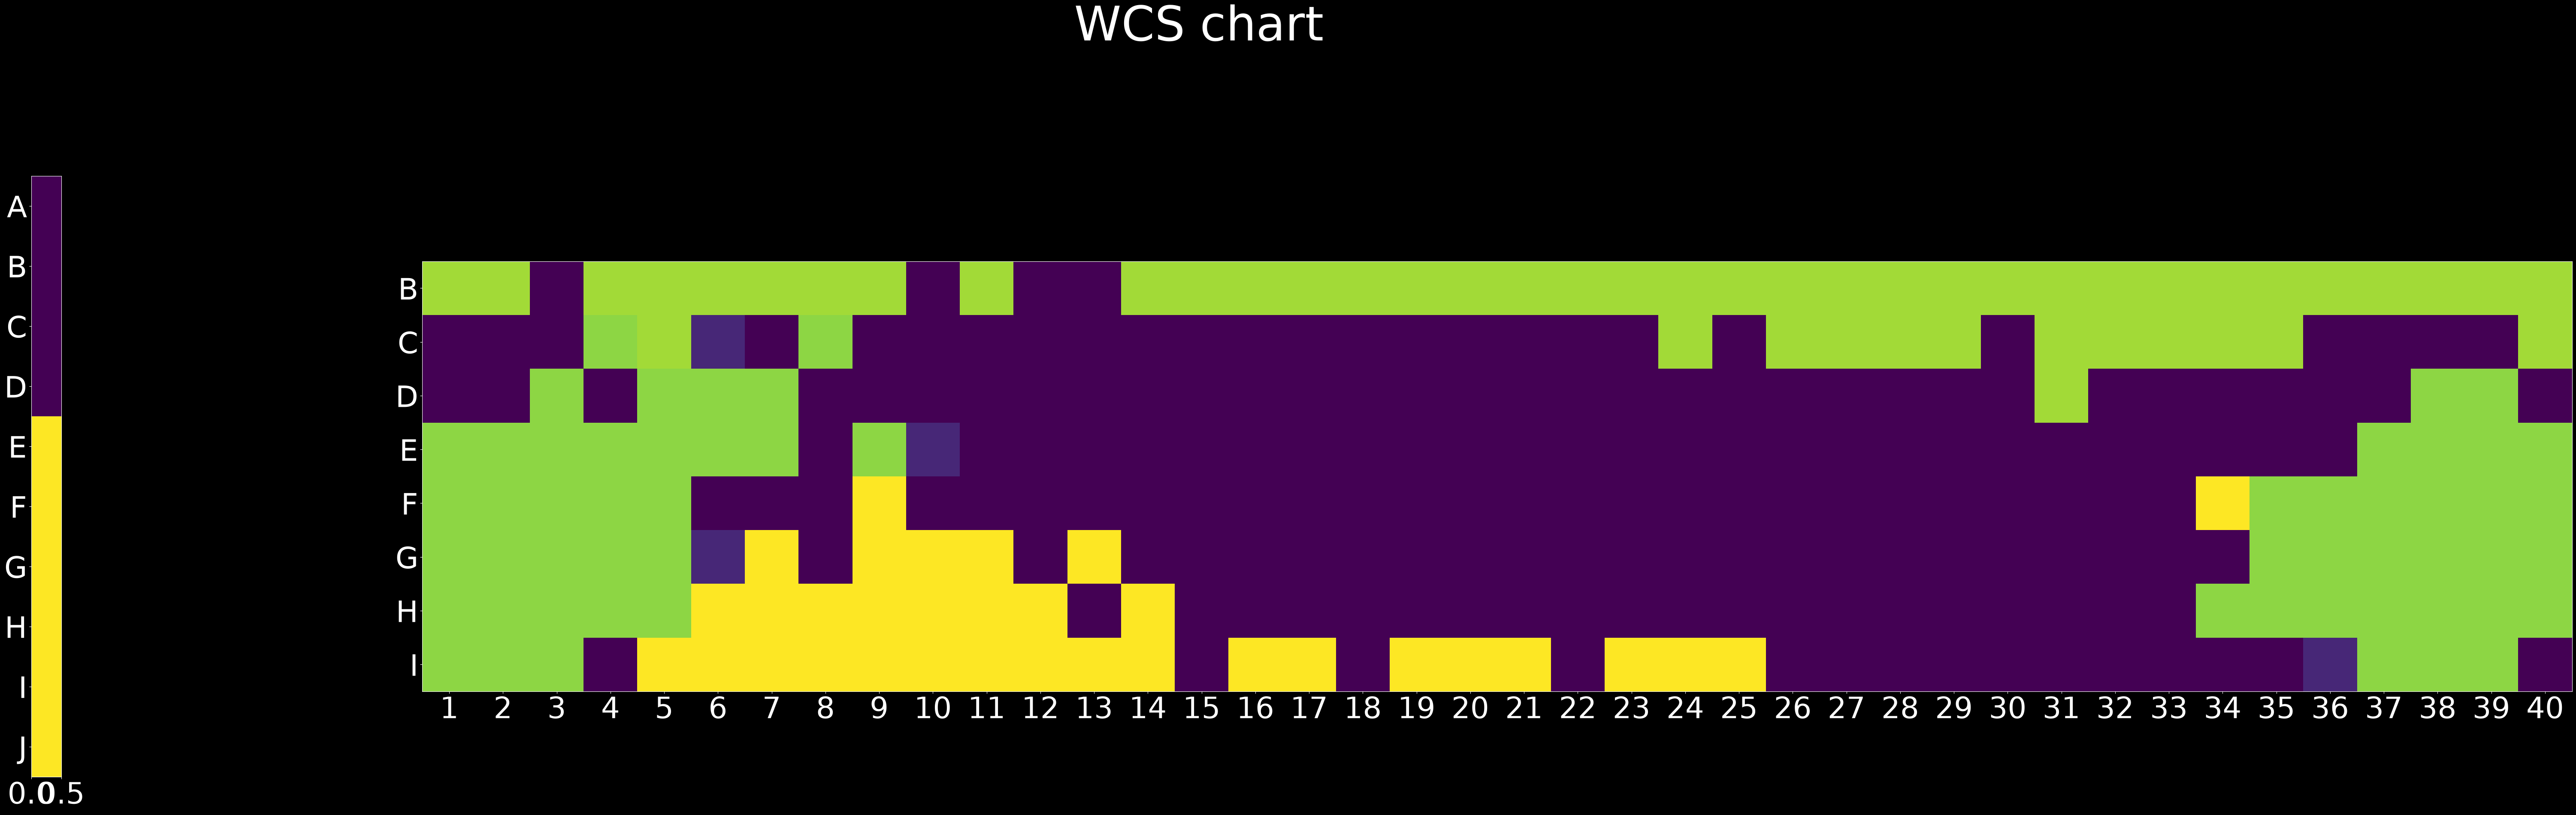

In [139]:
plotValues(encoded_terms)

**Note**: `plotValues()` is a generic function for visualizing various kinds of information on the chart, suited to needs.

Now you are in a position to start exploring this data set - enjoy!

In [140]:
# count the number of established color terms of the languages, which we define a language complexity
# for each language, keep record of how many times a term gloss appears as a term used by a speaker to name a Munsell chip
color_words_across_all_languages = dict()
total_languages = len(namingData)
language = 1
while language < total_languages + 1:
    speakers = namingData[language]
    color_words_per_language = dict()
    # print(len(speakers))
    for speaker in speakers:
        speaker_terms = set(namingData[language][speaker].values())
        for color in speaker_terms:
            if color not in color_words_per_language:
                color_words_per_language[color] = 1
            else:
                color_words_per_language[color] += 1
    # print(language_color_words)
    # number of established terms = the terms that majority of the speakers use
    num_establish_terms = 0
    for color_word in color_words_per_language.keys():
        if color_word != '*' and color_words_per_language[color_word] >= 0.5 * len(speakers):
            num_establish_terms += 1
    color_words_across_all_languages['language ' + str(language)] = num_establish_terms
    language += 1
print(color_words_across_all_languages)

{'language 1': 7, 'language 2': 6, 'language 3': 10, 'language 4': 9, 'language 5': 7, 'language 6': 8, 'language 7': 14, 'language 8': 7, 'language 9': 7, 'language 10': 7, 'language 11': 7, 'language 12': 5, 'language 13': 7, 'language 14': 4, 'language 15': 8, 'language 16': 6, 'language 17': 15, 'language 18': 7, 'language 19': 11, 'language 20': 8, 'language 21': 6, 'language 22': 6, 'language 23': 4, 'language 24': 10, 'language 25': 7, 'language 26': 8, 'language 27': 14, 'language 28': 8, 'language 29': 7, 'language 30': 6, 'language 31': 5, 'language 32': 4, 'language 33': 7, 'language 34': 9, 'language 35': 8, 'language 36': 3, 'language 37': 7, 'language 38': 10, 'language 39': 11, 'language 40': 7, 'language 41': 6, 'language 42': 7, 'language 43': 4, 'language 44': 9, 'language 45': 7, 'language 46': 11, 'language 47': 6, 'language 48': 7, 'language 49': 8, 'language 50': 6, 'language 51': 7, 'language 52': 10, 'language 53': 5, 'language 54': 7, 'language 55': 9, 'languag

In [141]:
# now we want to examine color naming consistency across the 330 Munsell chips for
# so we will check what does each speaker in each language name a chip as.

total_chips = 330 # assumes all speakers in every language is asked to name all 330 Munsell chips
color_naming_consistency_across_languages = dict()
# across the 110 languages
for language in range(1, total_languages + 1):
    # across the speakers in the language
    speakers = namingData[language]
    # keep track of color naming of all the 330 Munsell chips by the speakers in the language
    color_naming_all_chips = dict()
    # across the 330 chips
    for chip in range(1, total_chips + 1):
        # store the color naming for each chip
        chip_naming = []
        color_naming_per_chip = dict()
        for speaker in range(1, len(speakers) + 1):
            chip_naming.append(namingData[language][speaker][chip])
        # print(chip_naming)

        # store the proportion of the speakers name each chip with a color word
        for color in chip_naming:
            if color not in color_naming_per_chip:
                color_naming_per_chip[color] = 1/len(speakers)
            else:
                color_naming_per_chip[color] += 1/len(speakers)
        # print(color_naming_per_chip)
        color_naming_all_chips['chip ' + str(chip)] = color_naming_per_chip
    # print(color_naming_all_chips)

    # quantify the consistency in color naming for each language
    language_consistency = sum(max(chip.values()) for chip in color_naming_all_chips.values())/len(color_naming_all_chips)
    # print(language_consistency)
    color_naming_consistency_across_languages['language ' + str(language)] = language_consistency
print(color_naming_consistency_across_languages)

{'language 1': 0.5500606060606061, 'language 2': 0.5299242424242423, 'language 3': 0.4627878787878788, 'language 4': 0.6144588744588746, 'language 5': 0.7388888888888888, 'language 6': 0.5233445566778899, 'language 7': 0.6710303030303031, 'language 8': 0.6113939393939395, 'language 9': 0.6687878787878787, 'language 10': 0.5869090909090909, 'language 11': 0.6501818181818183, 'language 12': 0.7860606060606061, 'language 13': 0.6163636363636363, 'language 14': 0.7521212121212123, 'language 15': 0.666909090909091, 'language 16': 0.6790303030303031, 'language 17': 0.6182828282828283, 'language 18': 0.4575757575757576, 'language 19': 0.6943030303030304, 'language 20': 0.7261707988980718, 'language 21': 0.7633939393939395, 'language 22': 0.6621818181818183, 'language 23': 0.7098181818181819, 'language 24': 0.7271515151515152, 'language 25': 0.8761212121212123, 'language 26': 0.6912727272727274, 'language 27': 0.5655757575757576, 'language 28': 0.6373333333333334, 'language 29': 0.787030303030

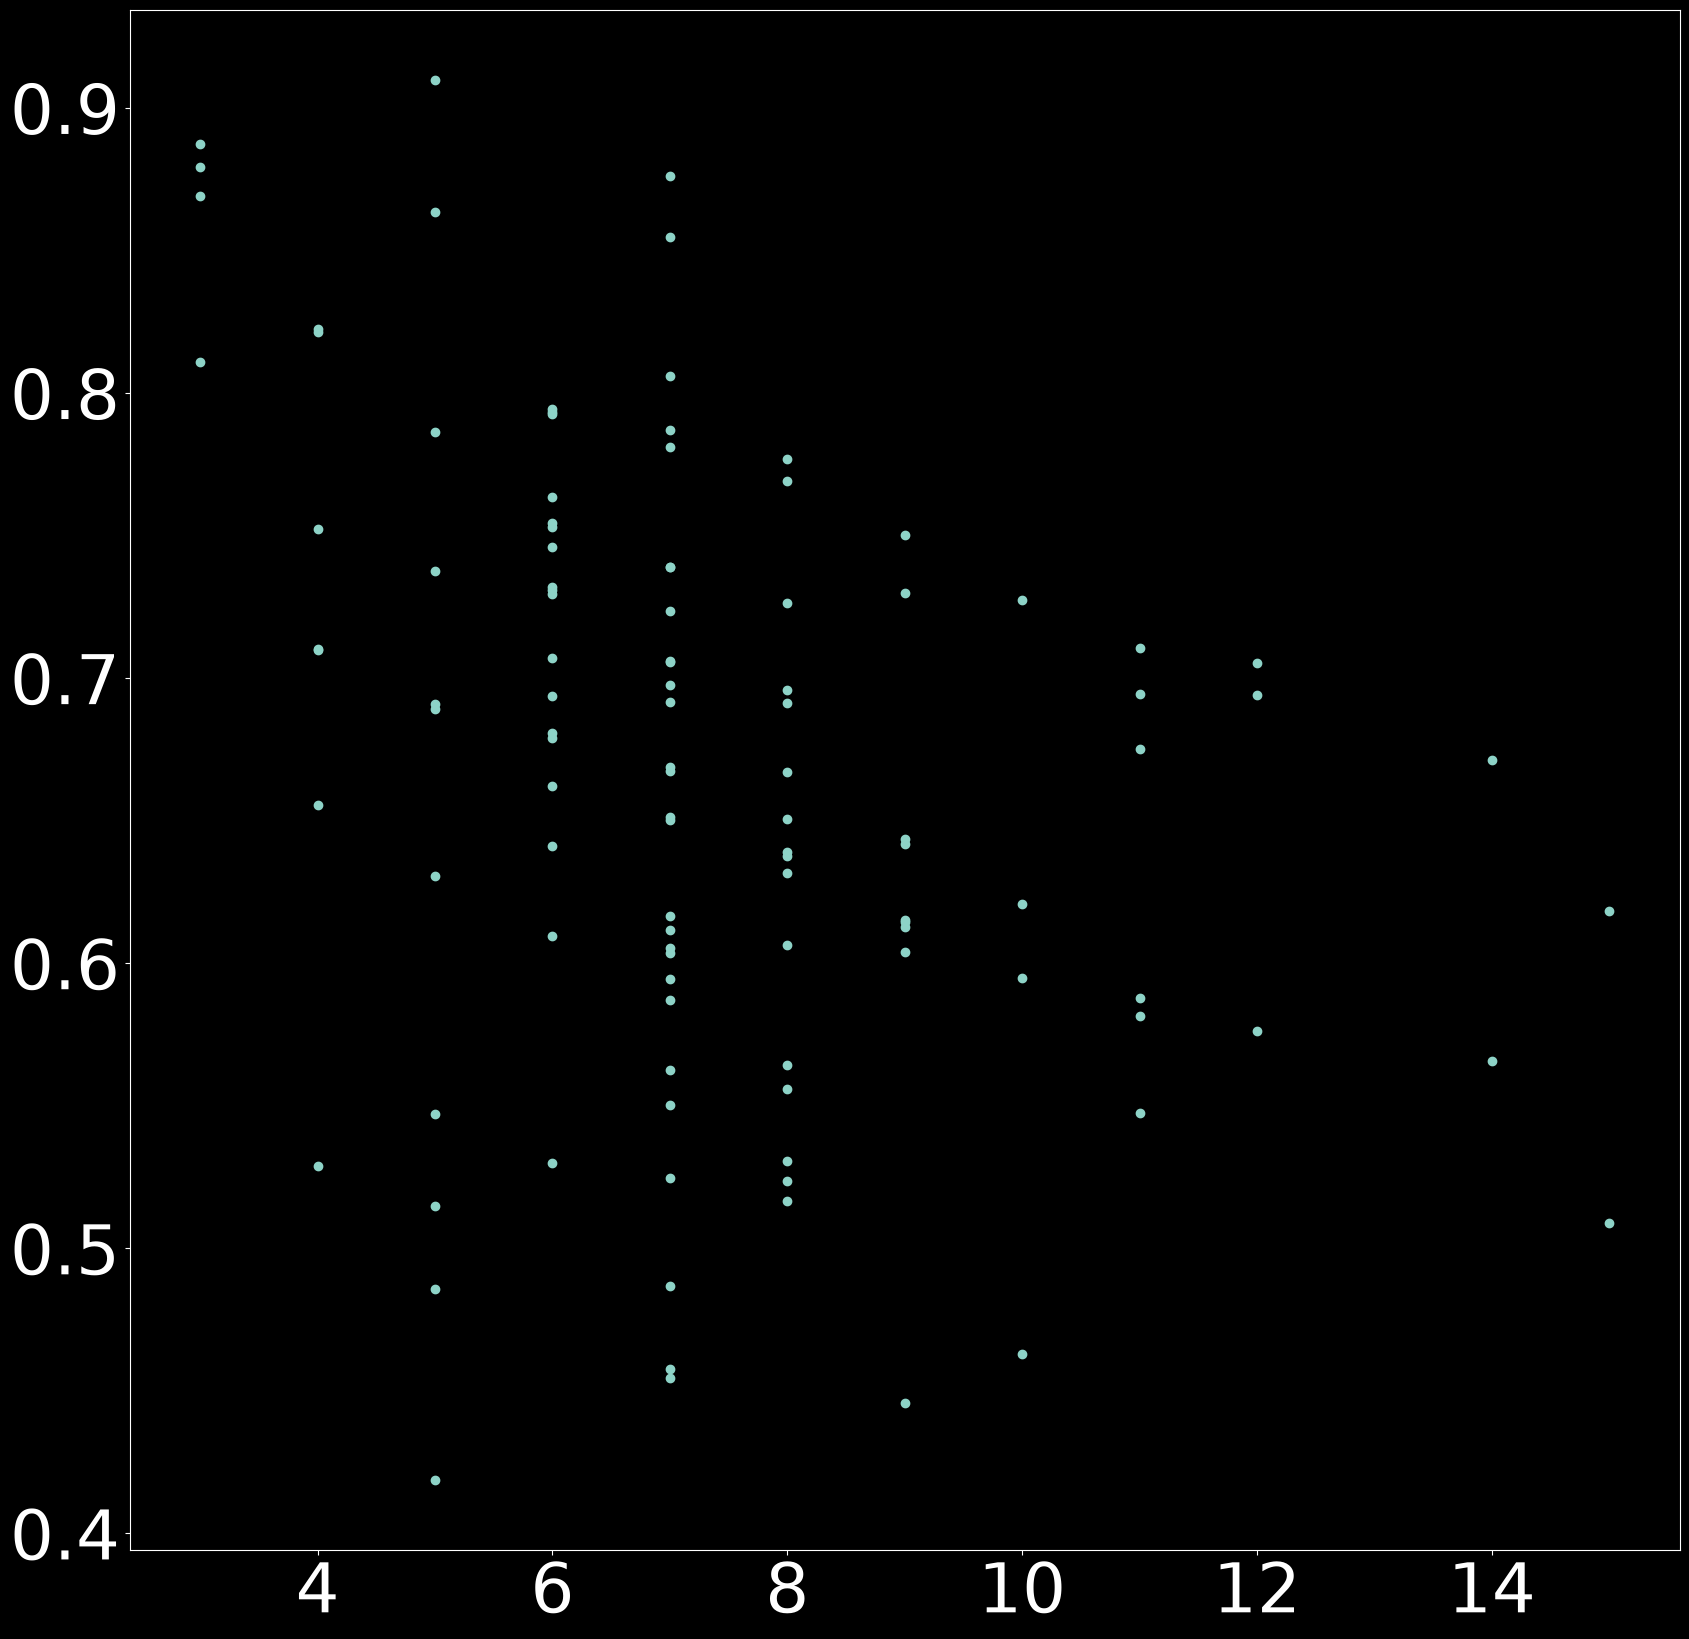

-0.34633645352011316


In [143]:
import scipy

# now we have to examine the correlation between the language complexity, define as the number of established color terms, and the color naming consistency.
x = [] # language complexity
y = [] # color naming consistency

for _, num in color_words_across_all_languages.items():
    x.append(num)

for _, val in color_naming_consistency_across_languages.items():
    y.append(val)
# plotting language complexity against color naming consistency
plt.figure(figsize=(20, 20))
plt.scatter(x, y)
plt.show()

# the correlation coefficient:
corr = scipy.stats.pearsonr(x, y)
print(corr.statistic)